# 2022 — Latent Diffusion (Stable Diffusion) and Classifier-Free Guidance

**Papers:** Robin Rombach, Andreas Blattmann, Dominik Lorenz, Patrick Esser & Björn Ommer, *"High-Resolution Image Synthesis with Latent Diffusion Models"*, CVPR (2022). Jonathan Ho & Tim Salimans, *"Classifier-Free Diffusion Guidance"* (2022).

Pixel-space diffusion (notebook 50) runs a big denoiser on every pixel at every one of many sampling steps. Most of that compute models imperceptible detail. **Latent diffusion** splits the problem:

1. Train an **autoencoder** once: it compresses an image $x$ to a much smaller latent $z = E(x)$ (8× smaller per side in Stable Diffusion: 512×512×3 → 64×64×4) and reconstructs it, $D(z)\approx x$. A small KL term (or VQ, notebook 39) keeps the latent space well behaved.
2. Train the **diffusion model in latent space**. Sampling denoises $z$, and the decoder turns the result into pixels once at the end.

Stable Diffusion (August 2022) combined this with text conditioning through cross-attention and released the weights, which made high-quality image generation run on consumer GPUs.

**Classifier-free guidance (CFG)** is the other ingredient behind every modern text-to-image model. Train one network both conditionally and unconditionally (drop the condition ~10% of the time). At sampling time, push the prediction away from the unconditional one:

$$\hat\epsilon = \epsilon(z_t, \varnothing) + w\,\big(\epsilon(z_t, c) - \epsilon(z_t, \varnothing)\big)$$

$w=1$ is plain conditional sampling; $w>1$ trades diversity for fidelity to the condition.

![Diagram: Latent diffusion and classifier-free guidance (Rombach et al.; Ho & Salimans, 2022)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/56_2022_latent_diffusion.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]

## Stage 1: the autoencoder (16×16×1 → 4×4×4)

In [3]:
class AE(nn.Module):
    def __init__(self, zc=4):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, 32, 3, 2, 1), nn.SiLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.SiLU(), nn.Conv2d(64, 2 * zc, 1))
        self.dec = nn.Sequential(nn.Conv2d(zc, 64, 3, padding=1), nn.SiLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.SiLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1))
    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, 1); return mu, logvar
    def forward(self, x):
        mu, logvar = self.encode(x); z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
        kl = 0.5 * (mu ** 2 + logvar.exp() - 1 - logvar).mean()
        return torch.sigmoid(self.dec(z)), kl
seed_everything(0); ae = AE().to(device); opt = torch.optim.Adam(ae.parameters(), lr=2e-3)
for s in range(3000):
    x = Xtr[torch.randint(0, len(Xtr), (128,), device=device)]
    xh, kl = ae(x); loss = F.mse_loss(xh, x) + 1e-3 * kl; opt.zero_grad(); loss.backward(); opt.step()
ae.eval()
with torch.no_grad():
    mu_tr = ae.encode(Xtr)[0]; scale = mu_tr.std().item()                     # SD also rescales latents to unit variance
    rec = torch.sigmoid(ae.dec(ae.encode(Xte)[0]))
print(f"latent: 4×4×4 = 64 numbers per image (pixels: 256); reconstruction MSE {F.mse_loss(rec, Xte).item():.4f}; latent scale factor {scale:.3f}")

latent: 4×4×4 = 64 numbers per image (pixels: 256); reconstruction MSE 0.0003; latent scale factor 0.847


## Stage 2: the same diffusion model in pixel space and in latent space
Both use the DDPM noise-prediction objective (notebook 50) with a class-conditional denoiser of the same design (a small conv net with time and class embeddings). The class embedding is replaced by a learned "null" class 10% of the time, which is all CFG needs.

In [4]:
T = 200
betas = torch.linspace(1e-4, 0.03, T, device=device); alphas = 1 - betas; abar = torch.cumprod(alphas, 0)

class Denoiser(nn.Module):
    def __init__(self, c, width=96):
        super().__init__()
        self.t_emb = nn.Sequential(nn.Linear(32, width), nn.SiLU(), nn.Linear(width, width)); self.y_emb = nn.Embedding(11, width)   # class 10 = "no condition"
        self.inp = nn.Conv2d(c, width, 3, padding=1)
        self.blocks = nn.ModuleList([nn.Sequential(nn.GroupNorm(8, width), nn.SiLU(), nn.Conv2d(width, width, 3, padding=1)) for _ in range(4)])
        self.out = nn.Conv2d(width, c, 3, padding=1)
    def forward(self, x, t, y):
        f = torch.exp(-math.log(1000) * torch.arange(16, device=x.device) / 16) * t[:, None]
        e = (self.t_emb(torch.cat([f.sin(), f.cos()], 1)) + self.y_emb(y))[..., None, None]
        h = self.inp(x)
        for b in self.blocks: h = h + b(h + e)
        return self.out(h)

def macs(model, shape):
    total = []
    hooks = [m.register_forward_hook(lambda mod, i, o: total.append(o.numel() * mod.in_channels * mod.kernel_size[0] * mod.kernel_size[1])) for m in model.modules() if isinstance(m, nn.Conv2d)]
    with torch.no_grad(): model(torch.zeros(shape, device=device), torch.zeros(1, device=device), torch.zeros(1, dtype=torch.long, device=device))
    for h in hooks: h.remove()
    return sum(total)

def train_diffusion(data, c, steps=4000):
    seed_everything(0); net = Denoiser(c).to(device); opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=steps, pct_start=0.05); t0 = time.time()
    for s in range(steps):
        i = torch.randint(0, len(data), (128,), device=device); x0, y = data[i], ytr[i].clone()
        y[torch.rand(len(y), device=device) < 0.1] = 10                       # condition dropout for CFG
        t = torch.randint(0, T, (len(i),), device=device); eps = torch.randn_like(x0)
        xt = abar[t].sqrt()[:, None, None, None] * x0 + (1 - abar[t]).sqrt()[:, None, None, None] * eps
        loss = F.mse_loss(net(xt, t.float(), y), eps); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return net.eval(), time.time() - t0

pixel_net, t_pix = train_diffusion(Xtr * 2 - 1, 1)
latent_net, t_lat = train_diffusion(mu_tr / scale, 4)
print(f"denoiser MACs per sampling step: pixel {macs(pixel_net, (1, 1, 16, 16)) / 1e6:.1f}M vs latent {macs(latent_net, (1, 4, 4, 4)) / 1e6:.2f}M | training time {t_pix:.0f}s vs {t_lat:.0f}s")

@torch.no_grad()
def sample(net, shape, y, w=1.0, seed=0):
    g = torch.Generator(device="cpu").manual_seed(seed); x = torch.randn(shape, generator=g).to(device)
    for t in reversed(range(T)):
        tt = torch.full((shape[0],), float(t), device=device)
        e_c, e_u = net(x, tt, y), net(x, tt, torch.full_like(y, 10))
        eps = e_u + w * (e_c - e_u)                                            # classifier-free guidance
        x = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0: x = x + betas[t].sqrt() * torch.randn(shape, generator=g).to(device)
    return x
def pixel_samples(y, w): return ((sample(pixel_net, (len(y), 1, 16, 16), y, w) + 1) / 2).clamp(0, 1)
@torch.no_grad()
def latent_samples(y, w): return torch.sigmoid(ae.dec(sample(latent_net, (len(y), 4, 4, 4), y, w) * scale))

denoiser MACs per sampling step: pixel 85.4M vs latent 5.42M | training time 148s vs 17s


## Measuring samples with a digit classifier
A separately trained CNN classifies each generated image. **Class accuracy**: does the sample show the requested digit? **Diversity**: average pixel distance between two samples of the same class (higher is more varied).

In [5]:
seed_everything(0)
judge = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 16, 10)).to(device)
opt = torch.optim.Adam(judge.parameters(), lr=1e-3)
for s in range(1500):
    i = torch.randint(0, len(Xtr), (128,), device=device); loss = F.cross_entropy(judge(Xtr[i]), ytr[i]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()
with torch.no_grad(): print(f"judge accuracy on real test digits: {(judge(Xte).argmax(1) == yte).float().mean().item():.3f}")
def score(imgs, y):
    with torch.no_grad(): acc = (judge(imgs).argmax(1) == y).float().mean().item()
    div = np.mean([torch.pdist(imgs[y == k].flatten(1).cpu()).mean().item() for k in range(10)])
    return acc, div
y = torch.arange(10, device=device).repeat_interleave(20)
results = {}
for name, fn in [("pixel diffusion", pixel_samples), ("latent diffusion", latent_samples)]:
    for w in [0.0, 1.0, 3.0]:
        results[(name, w)] = fn(y, w); acc, div = score(results[(name, w)], y)
        print(f"{name:16s} guidance w = {w:3.1f}: class accuracy {acc:.3f}, diversity {div:.2f}")

judge accuracy on real test digits: 0.978


pixel diffusion  guidance w = 0.0: class accuracy 0.100, diversity 4.73


pixel diffusion  guidance w = 1.0: class accuracy 0.550, diversity 4.08


pixel diffusion  guidance w = 3.0: class accuracy 0.920, diversity 3.42


latent diffusion guidance w = 0.0: class accuracy 0.100, diversity 4.34


latent diffusion guidance w = 1.0: class accuracy 0.965, diversity 3.04


latent diffusion guidance w = 3.0: class accuracy 1.000, diversity 2.73


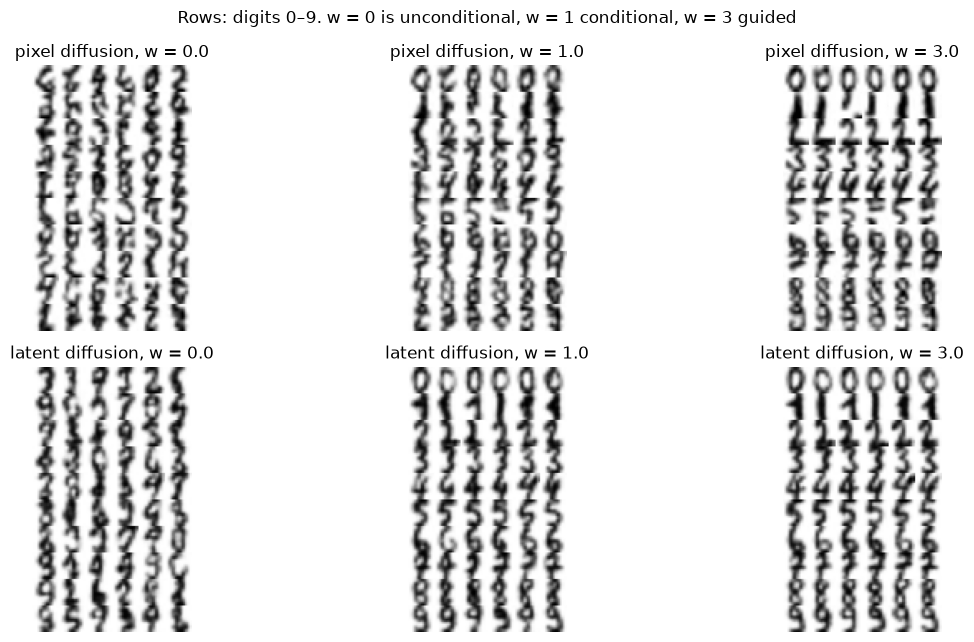

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for r, name in enumerate(["pixel diffusion", "latent diffusion"]):
    for c, w in enumerate([0.0, 1.0, 3.0]):
        imgs = results[(name, w)].view(10, 20, 1, 16, 16)[:, :6].permute(0, 3, 1, 4, 2).reshape(160, 96)
        axes[r, c].imshow(imgs.cpu(), cmap="gray_r"); axes[r, c].axis("off"); axes[r, c].set_title(f"{name}, w = {w}")
plt.suptitle("Rows: digits 0–9. w = 0 is unconditional, w = 1 conditional, w = 3 guided"); plt.tight_layout(); plt.show()

## Takeaways
- **Compress first, then diffuse.** The latent denoiser works on 64 numbers instead of 256 and costs a fraction of the pixel model per step; at Stable Diffusion's scale the saving (48× fewer values per image) is what made high-resolution generation affordable. The decoder runs once per image.
- **The autoencoder sets the ceiling.** Latent samples can never be sharper than what the decoder can reconstruct; that is why SD3 and Flux moved to 16-channel latents, and why video models invest heavily in their latent autoencoders.
- **CFG** turns one network into a dial between diversity and fidelity: $w=0$ ignores the class, and larger $w$ raises class accuracy while samples become more uniform.
- Modern image and video models (SD3, Flux, Sora-style video models) are latent models with CFG; their denoisers became Transformers (DiT, notebook 61) trained with flow matching (notebook 55).